<a href="https://colab.research.google.com/github/Fdiannz/BT4222-Project-Group-4--MIND/blob/main/step3_features.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# step3_features: Feature engineering for the feature-based MLP

**Owner:** P4

**Dataset:** MIND-large

**Purpose:** build one row of leak-free features for every candidate article in every impression, for the feature-based MLP (`step3_feature_mlp`).

**Inputs** (`data/processed/`, from step 1): `news_metadata`, `{fit,tune,eval}_impressions` (click histories and full slates), `fit_candidates_sampled`, `tune_candidates`, `eval_candidates`.

**Outputs** (shared Drive):

| File | Contents |
|---|---|
| `data/processed/features_{fit,tune,eval}.parquet` | One row per candidate: keys, label, cold flag and the 7 features below |
| `data/processed/step3_category_vocab.json` | Fit-only category and subcategory IDs (0 = unseen) |
| `data/processed/step3_article_first_seen.parquet` | First display time of every article |
| `data/embeddings/news_embeddings.npy` + `news_embedding_ids.parquet` | MiniLM (all-MiniLM-L6-v2) 384-d embedding of each article's title + abstract |

### Features

| Feature | Group | Definition | Why it is leak-free |
|---|---|---|---|
| `category_idx`, `subcategory_idx` | News | Category and subcategory IDs from the Fit vocabulary | Vocabulary built from Fit only; unseen values map to 0 |
| `hist_len` | User | Number of articles in the user's click history | Histories contain clicks before 9 Nov only |
| `cat_match` | User × news | Share of the user's history in the candidate's category | Uses the history and article metadata only |
| `user_article_sim` | User × news | Cosine similarity between the mean MiniLM embedding of the history and the candidate's embedding | Pre-trained text model; no clicks or labels |
| `slate_exposure_pct` | News | Rank of the candidate's prior display count within its full displayed slate (0 = least shown, 1 = most) | Counts use displays on earlier days only |
| `log_article_age_hours` | Context | log(1 + hours since the article was first displayed) | First display is never after the current impression |



## 1. Setup
Mount Google Drive, clone the team repository (shared `config.py` and `utils/`) and locate the processed data.

In [ ]:

# ==========================================================
# 1. GOOGLE COLAB SETUP
# ==========================================================

from google.colab import drive
drive.mount("/content/drive")

import os
import sys
import subprocess
import importlib
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import warnings, os
warnings.filterwarnings("ignore")
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"

# Locate or clone GitHub repository
PROJECT_ROOT = Path("/content/BT4222-Project-Group-4--MIND")

if not (PROJECT_ROOT / "config.py").exists():
    subprocess.run([
        "git", "clone", "--depth", "1",
        "https://github.com/Fdiannz/BT4222-Project-Group-4--MIND.git",
        str(PROJECT_ROOT)
    ], check=True)

sys.path.insert(0, str(PROJECT_ROOT))

# Shared Google Drive folder (the shortcut location can differ between members)
DATA_ROOT = None
for p in ["/content/drive/MyDrive/BT4222_Project", "/content/drive/MyDrive/BT4222 G4/BT4222_Project"]:
    if Path(p).is_dir():
        DATA_ROOT = Path(p)
        break
assert DATA_ROOT is not None, "Add a shortcut to BT4222_Project in My Drive (Shared with me -> Organise -> Add shortcut)"

os.environ["MIND_PROJECT_DIR"] = str(DATA_ROOT)

import config
importlib.reload(config)

PROCESSED_DIR = Path(config.PROCESSED_DIR)

# Validate paths
assert (PROJECT_ROOT / "config.py").exists()
assert DATA_ROOT.is_dir(), "Project folder not found"
assert PROCESSED_DIR.is_dir(), "Processed folder not found"

print("Repository found:", True)
print("Project folder found:", DATA_ROOT.is_dir())
print("Processed folder found:", PROCESSED_DIR.is_dir())
print("Setup successful!")

Mounted at /content/drive
Repository found: True
Project folder found: True
Processed folder found: True
Setup successful!


## 2. Inspect the step 1 data
Row counts and columns of the files used below.

In [ ]:
# ==========================================================
# 2. INSPECT PROCESSED DATA
# ==========================================================

required_files = [
    "news_metadata.parquet",
    "fit_impressions.parquet",
    "tune_impressions.parquet",
    "eval_impressions.parquet",
    "fit_candidates_sampled.parquet",
    "tune_candidates.parquet",
    "eval_candidates.parquet",
]

for filename in required_files:
    path = PROCESSED_DIR / filename

    if not path.exists():
        print(f"MISSING: {filename}")
        continue

    pf = pq.ParquetFile(path)

    print(f"\n=== {filename} ===")
    print(f"Rows: {pf.metadata.num_rows:,}")
    print("Columns:", pf.schema_arrow.names)

# Inspect impression history structure
for split in ["fit", "tune", "eval"]:
    path = PROCESSED_DIR / f"{split}_impressions.parquet"

    if not path.exists():
        continue

    pf = pq.ParquetFile(path)

    sample = next(
        pf.iter_batches(batch_size=2)
    ).to_pandas()

    print(f"\n=== {split.upper()} SAMPLE ===")
    display(sample)


=== news_metadata.parquet ===
Rows: 104,151
Columns: ['news_id', 'category', 'subcategory', 'title', 'abstract', 'url', 'title_entities', 'abstract_entities', 'news_idx']

=== fit_impressions.parquet ===
Rows: 1,801,231
Columns: ['impression_id', 'user_id', 'time', 'history', 'impressions', 'user_idx']

=== tune_impressions.parquet ===
Rows: 431,517
Columns: ['impression_id', 'user_id', 'time', 'history', 'impressions', 'user_idx']

=== eval_impressions.parquet ===
Rows: 376,471
Columns: ['impression_id', 'user_id', 'time', 'history', 'impressions', 'user_idx']

=== fit_candidates_sampled.parquet ===
Rows: 12,894,210
Columns: ['impression_id', 'user_id', 'user_idx', 'time', 'news_id', 'news_idx', 'label', 'prior_exposure_count', 'cold_article', 'category', 'subcategory']

=== tune_candidates.parquet ===
Rows: 17,400,106
Columns: ['impression_id', 'user_id', 'user_idx', 'time', 'news_id', 'news_idx', 'label', 'prior_exposure_count', 'cold_article', 'category', 'subcategory']

=== eval_

,impression_id,user_id,time,history,impressions,user_idx
0,1,U87243,2019-11-10 11:30:54,N8668 N39081 N65259 N79529 N73408 N43615 N2937...,N78206-0 N26368-0 N7578-0 N58592-0 N19858-0 N5...,1
1,2,U598644,2019-11-12 13:45:29,N56056 N8726 N70353 N67998 N83823 N111108 N107...,N47996-0 N82719-0 N117066-0 N8491-0 N123784-0 ...,2



=== TUNE SAMPLE ===


,impression_id,user_id,time,history,impressions,user_idx
0,5,U239687,2019-11-14 20:03:01,N65250 N122359 N71723 N53796 N41663 N41484 N11...,N76209-0 N48841-0 N67937-0 N62235-0 N6307-0 N3...,5
1,11,U108656,2019-11-14 06:51:18,N4833 N61319 N94639 N50163 N107002 N112041 N49...,N95301-0 N79081-0 N103133-0 N80281-0 N70363-0 ...,11



=== EVAL SAMPLE ===


,impression_id,user_id,time,history,impressions,user_idx
0,1,U134050,2019-11-15 08:55:22,N12246 N128820 N119226 N4065 N67770 N33446 N10...,N91737-0 N30206-0 N54368-0 N117802-0 N18190-0 ...,89712
1,2,U254959,2019-11-15 11:42:35,N34011 N9375 N67397 N7936 N118985 N109453 N103...,N119999-0 N24958-0 N104054-0 N33901-0 N9250-0 ...,516861


## 3. News features: category and subcategory IDs (Fit vocabulary)
Each category and subcategory seen in the Fit candidates gets an integer ID; anything first seen on the Tune or Test days maps to 0 (unseen). The vocabulary is saved so the MLP uses identical IDs.

In [ ]:
# ==========================================================
# 3. CATEGORY AND SUBCATEGORY MAPPINGS
# ==========================================================

import json

# Load article metadata
news_metadata = pd.read_parquet(
    PROCESSED_DIR / "news_metadata.parquet",
    columns=["news_id", "category", "subcategory"]
)

# Read FIT candidates in batches to limit memory usage
fit_file = pq.ParquetFile(
    PROCESSED_DIR / "fit_candidates_sampled.parquet"
)

fit_categories = set()
fit_subcategories = set()

for batch in fit_file.iter_batches(
    batch_size=100_000,
    columns=["category", "subcategory"]
):
    df = batch.to_pandas()

    fit_categories.update(
        df["category"].dropna().astype(str).unique()
    )

    fit_subcategories.update(
        df["subcategory"].dropna().astype(str).unique()
    )

# Create fit-only categorical vocabularies
# Reserve index 0 for unseen or missing categories
def build_vocab(values):
    clean = sorted(
        str(x) for x in values
        if str(x).strip()
    )
    return {value: i + 1 for i, value in enumerate(clean)}

category_to_idx = build_vocab(fit_categories)
subcategory_to_idx = build_vocab(fit_subcategories)

# Save the mappings so the MLP uses identical encodings
vocab_path = PROCESSED_DIR / "step3_category_vocab.json"

with open(vocab_path, "w", encoding="utf-8") as f:
    json.dump(
        {
            "category_to_idx": category_to_idx,
            "subcategory_to_idx": subcategory_to_idx
        },
        f,
        indent=2
    )

print("News metadata:", len(news_metadata))
print("FIT categories:", len(category_to_idx))
print("FIT subcategories:", len(subcategory_to_idx))
print("Vocabulary saved:", vocab_path)

display(news_metadata.head())

News metadata: 104151
FIT categories: 16
FIT subcategories: 218
Vocabulary saved: G:\.shortcut-targets-by-id\1D4Db1s7DJ5PVK9CFiV-pklpCW5dr1uOM\BT4222_Project\data\processed\step3_category_vocab.json


,news_id,category,subcategory
0,N88753,lifestyle,lifestyleroyals
1,N45436,news,newsscienceandtechnology
2,N23144,health,weightloss
3,N86255,health,medical
4,N93187,news,newsworld


## 4. User features (history length) and user × news features (category match)
- **`hist_len`:** number of articles in the user's click history.
- **`cat_match`:** share of those articles in the candidate's category (0 if the history is empty).

In [ ]:
# ==========================================================
# 4. USER-HISTORY FEATURE FUNCTIONS
# ==========================================================
#these are the personalised features

# Lookup: article ID -> article category
news_to_category = dict(
    zip(
        news_metadata["news_id"],
        news_metadata["category"]
    )
)

# Convert space-separated history into article IDs
def parse_history(history):
    if not isinstance(history, str) or not history.strip():
        return []
    return history.split()

# Feature 1: Number of previously clicked articles
def get_hist_len(history):
    return len(parse_history(history))

# Feature 2: Share of history matching candidate category
def get_cat_match(history, candidate_news_id):
    history_ids = parse_history(history)

    if not history_ids:
        return 0.0

    candidate_category = news_to_category.get(
        candidate_news_id
    )

    if pd.isna(candidate_category):
        return 0.0

    matches = sum(
        news_to_category.get(news_id) == candidate_category
        for news_id in history_ids
    )

    return matches / len(history_ids)

print("User-history feature functions ready.")

User-history feature functions ready.


Check the two functions on a small Fit sample.

In [ ]:
# ==========================================================
# 5. VALIDATE USER-HISTORY FEATURES
# ==========================================================
#testing the ffunctions on a small sample of FIT impressions

fit_impressions_file = pq.ParquetFile(
    PROCESSED_DIR / "fit_impressions.parquet"
)

sample = next(
    fit_impressions_file.iter_batches(
        batch_size=10,
        columns=["impression_id", "history", "impressions"]
    )
).to_pandas()

# Get the first displayed candidate from each impression
def first_candidate(impressions):
    if not isinstance(impressions, str) or not impressions.strip():
        return None

    first = impressions.split()[0]

    # Format: news_id-click_label
    return first.rsplit("-", 1)[0]


sample["candidate_news_id"] = (
    sample["impressions"].apply(first_candidate)
)

sample["hist_len"] = (
    sample["history"].apply(get_hist_len)
)

sample["cat_match"] = sample.apply(
    lambda row: get_cat_match(
        row["history"],
        row["candidate_news_id"]
    ),
    axis=1
)

display(
    sample[
        [
            "impression_id",
            "candidate_news_id",
            "hist_len",
            "cat_match"
        ]
    ]
)

# Basic validation
assert (sample["hist_len"] >= 0).all()
assert sample["cat_match"].between(0, 1).all()

print("History feature validation passed!")

FIT rows: 12894210
FIT row groups: 133


## 5. Article text embeddings (MiniLM), used for the user × news similarity
Each article's title and abstract are encoded with the pre-trained sentence encoder all-MiniLM-L6-v2 (384-d, normalised). The model is not trained on our data, so the embeddings use no clicks or labels.

In [ ]:
#%pip install sentence-transformers

   ---------------------------------------- 0.0/760.7 kB ? eta -:--:--
   --------------------------------------- 760.7/760.7 kB 16.1 MB/s eta 0:00:00
   ---------------------------------------- 0.0/857.0 kB ? eta -:--:--
   --------------------------------------- 857.0/857.0 kB 19.2 MB/s eta 0:00:00
   ---------------------------------------- 0.0/2.9 MB ? eta -:--:--
   ---------------------------------------- 2.9/2.9 MB 18.5 MB/s eta 0:00:00
   ---------------------------------------- 0.0/13.1 MB ? eta -:--:--
   ------------ --------------------------- 4.2/13.1 MB 25.2 MB/s eta 0:00:01
   ---------------------------------------  12.8/13.1 MB 33.6 MB/s eta 0:00:01
   ---------------------------------------- 13.1/13.1 MB 30.3 MB/s eta 0:00:00
   ---------------------------------------- 0.0/3.9 MB ? eta -:--:--
   ---------------------------------------- 3.9/3.9 MB 29.2 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Load the encoder (GPU if available).

In [ ]:
# ==========================================================
# 6. ARTICLE TEXT EMBEDDINGS - SETUP
# ==========================================================

from pathlib import Path
import torch
from sentence_transformers import SentenceTransformer

# Store embeddings separately from processed features
EMBEDDINGS_DIR = PROCESSED_DIR.parent / "embeddings"
EMBEDDINGS_DIR.mkdir(parents=True, exist_ok=True)

# Use GPU if available
device = "cuda" if torch.cuda.is_available() else "cpu"

print("Using device:", device)

# Pretrained model for semantic text embeddings
embedding_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2",
    device=device
)

print("Embedding model loaded successfully.")
print("Embedding dimensions:",
      embedding_model.get_embedding_dimension())


Using device: cpu


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (5 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedding model loaded successfully.
Embedding dimensions: 384


Join title and abstract; missing text becomes an empty string.

In [ ]:

# ==========================================================
# 7. PREPARE ARTICLE TEXT
# ==========================================================

news_text = pd.read_parquet(
    PROCESSED_DIR / "news_metadata.parquet",
    columns=["news_id", "title", "abstract"]
)

# Ensure one embedding per unique article
news_text = (
    news_text
    .dropna(subset=["news_id"])
    .drop_duplicates(subset=["news_id"])
    .sort_values("news_id")
    .reset_index(drop=True)
)

# Handle missing text safely
news_text["title"] = (
    news_text["title"].fillna("").astype(str)
)

news_text["abstract"] = (
    news_text["abstract"].fillna("").astype(str)
)

news_text["article_text"] = (
    news_text["title"].str.strip()
    + ". "
    + news_text["abstract"].str.strip()
).str.strip()

print("Total unique articles:", len(news_text))
print("Missing/empty text:",
      (news_text["article_text"] == "").sum())

display(
    news_text[
        ["news_id", "title", "abstract"]
    ].head()
)

Total unique articles: 104151
Missing/empty text: 0


,news_id,title,abstract
0,N1,Texans defensive tackle D.J. Reader is taking ...,Houston Texans defensive tackle D.J. Reader is...
1,N100,Fed Seen Cutting Rates Next Week and Then Hitt...,Federal Reserve officials will signal they're ...
2,N1000,Severe Weather Leaves Thousands Without Power,There were tense moments overnight as the Nati...
3,N10000,Stars attend the 2019 Governors Awards for the...,See which celebs attended the 2019 Governors A...
4,N100000,Ahkello Witherspoon likely to return Week 11 v...,Witherspoon practiced Friday


Test the encoder on five articles.

In [ ]:

# ==========================================================
# 8. TEST ARTICLE EMBEDDINGS
# ==========================================================

test_texts = news_text["article_text"].head(5).tolist()

test_embeddings = embedding_model.encode(
    test_texts,
    convert_to_numpy=True,
    normalize_embeddings=True
)

print("Test embedding shape:", test_embeddings.shape)

assert test_embeddings.shape == (5, 384)
assert np.isfinite(test_embeddings).all()

print("Article embedding test passed!")

Test embedding shape: (5, 384)
Article embedding test passed!


Encode all 104,151 articles once and cache the result on Drive (skipped if the files already exist).

In [ ]:
# ==========================================================
# 9. GENERATE AND SAVE ALL ARTICLE EMBEDDINGS
# ==========================================================

from pathlib import Path

embeddings_path = EMBEDDINGS_DIR / "news_embeddings.npy"
ids_path = EMBEDDINGS_DIR / "news_embedding_ids.parquet"

# Avoid repeating the expensive encoding process
if embeddings_path.exists() and ids_path.exists():
    print("Existing embedding files found. Validating...")

    news_embeddings = np.load(
        embeddings_path, mmap_mode="r"
    )
    saved_ids = pd.read_parquet(ids_path)

    assert news_embeddings.shape == (len(news_text), 384)
    assert saved_ids["news_id"].tolist() == (
        news_text["news_id"].tolist()
    )

    print("Existing embeddings are valid. Skipping generation.")

else:
    if embeddings_path.exists() != ids_path.exists():
        raise FileNotFoundError(
            "Only one embedding file exists. "
            "Check the embedding folder before rerunning."
        )

    print(f"Generating embeddings for {len(news_text):,} articles...")

    # Smaller batches for CPU; larger batches for GPU
    batch_size = 128 if device == "cuda" else 32

    news_embeddings = embedding_model.encode(
        news_text["article_text"].tolist(),
        batch_size=batch_size,
        convert_to_numpy=True,
        normalize_embeddings=True,
        show_progress_bar=True
    ).astype(np.float32)

    # Validate before saving
    assert news_embeddings.shape == (len(news_text), 384)
    assert np.isfinite(news_embeddings).all()

    # Save embeddings
    np.save(embeddings_path, news_embeddings)

    # Save article IDs in the exact same row order
    pd.DataFrame({
        "news_id": news_text["news_id"]
    }).to_parquet(ids_path, index=False)

    print("All embeddings generated and saved!")

print("\n=== FINAL EMBEDDING CHECK ===")
print("Embedding shape:", news_embeddings.shape)
print("Embedding file:", embeddings_path)
print("Article ID file:", ids_path)
print("Number of article IDs:", len(news_text))


Generating embeddings for 104,151 articles...


Batches: 100%|██████████| 3255/3255 [1:04:10<00:00,  1.18s/it]  


All embeddings generated and saved!

=== FINAL EMBEDDING CHECK ===
Embedding shape: (104151, 384)
Embedding file: G:\.shortcut-targets-by-id\1D4Db1s7DJ5PVK9CFiV-pklpCW5dr1uOM\BT4222_Project\data\embeddings\news_embeddings.npy
Article ID file: G:\.shortcut-targets-by-id\1D4Db1s7DJ5PVK9CFiV-pklpCW5dr1uOM\BT4222_Project\data\embeddings\news_embedding_ids.parquet
Number of article IDs: 104151


Load the cached embeddings and map each `news_id` to its row.

In [ ]:

# ==========================================================
# 10. LOAD EMBEDDINGS AND CREATE ARTICLE LOOKUP
# ==========================================================

# Load the saved article embeddings
news_embeddings = np.load(
    EMBEDDINGS_DIR / "news_embeddings.npy",
    mmap_mode="r"
)

embedding_ids = pd.read_parquet(
    EMBEDDINGS_DIR / "news_embedding_ids.parquet"
)

# Each article ID points to its corresponding embedding row
news_to_embedding_idx = {
    str(news_id): idx
    for idx, news_id in enumerate(embedding_ids["news_id"])
}

# Validation
assert len(embedding_ids) == len(news_embeddings)
assert embedding_ids["news_id"].is_unique

print("Embeddings loaded:", news_embeddings.shape)
print("Article IDs mapped:", len(news_to_embedding_idx))
print("Article lookup ready!")

Embeddings loaded: (104151, 384)
Article IDs mapped: 104151
Article lookup ready!


## 6. User × news features: content similarity
**`user_article_sim`** = cosine similarity between the user's profile (mean embedding of the clicked articles, normalised) and the candidate's embedding. Users with no history, or candidates without an embedding, get 0.

In [ ]:
# ==========================================================
# 11. USER-ARTICLE SEMANTIC SIMILARITY
# ==========================================================

def get_user_profile(history):
    """
    Represent a user's interests using the mean embedding
    of articles clicked before the current impression.
    """

    history_ids = parse_history(history)

    # Find articles with available embeddings
    indices = [
        news_to_embedding_idx[nid]
        for nid in history_ids
        if nid in news_to_embedding_idx
    ]

    if not indices:
        return None

    # Average previously clicked article embeddings
    profile = np.asarray(
        news_embeddings[indices],
        dtype=np.float32
    ).mean(axis=0)

    # Normalise for cosine similarity
    norm = np.linalg.norm(profile)

    if norm == 0:
        return None

    return profile / norm


def get_user_article_sim(history, candidate_news_id):
    """
    Calculate cosine similarity between the user's
    reading history and a candidate article.
    """

    user_profile = get_user_profile(history)

    candidate_idx = news_to_embedding_idx.get(
        str(candidate_news_id)
    )

    # Missing history or missing candidate embedding
    if user_profile is None or candidate_idx is None:
        return 0.0

    candidate_embedding = news_embeddings[candidate_idx]

    similarity = np.dot(
        user_profile,
        candidate_embedding
    )

    return float(np.clip(similarity, -1.0, 1.0))


print("User-article similarity functions ready!")


User-article similarity functions ready!


Check the similarity on a small sample.

In [ ]:

# ==========================================================
# 12. VALIDATE USER-ARTICLE SIMILARITY
# ==========================================================

# Load a small sample directly from P1's FIT impressions
fit_impressions_file = pq.ParquetFile(
    PROCESSED_DIR / "fit_impressions.parquet"
)

sample = next(
    fit_impressions_file.iter_batches(
        batch_size=10,
        columns=["impression_id", "history", "impressions"]
    )
).to_pandas()

# Extract the first candidate news ID from each impression
def first_candidate(impressions):
    if not isinstance(impressions, str) or not impressions.strip():
        return None

    first = impressions.split()[0]
    return first.rsplit("-", 1)[0]

sample["candidate_news_id"] = (
    sample["impressions"].apply(first_candidate)
)

# Calculate history length
sample["hist_len"] = (
    sample["history"].apply(get_hist_len)
)

# Calculate category matching
sample["cat_match"] = sample.apply(
    lambda row: get_cat_match(
        row["history"],
        row["candidate_news_id"]
    ),
    axis=1
)

# Calculate semantic similarity
sample["user_article_sim"] = [
    get_user_article_sim(history, news_id)
    for history, news_id in zip(
        sample["history"],
        sample["candidate_news_id"]
    )
]

# Display results
display(
    sample[
        [
            "impression_id",
            "candidate_news_id",
            "hist_len",
            "cat_match",
            "user_article_sim"
        ]
    ]
)

# Validate features
assert (sample["hist_len"] >= 0).all()
assert sample["cat_match"].between(0, 1).all()
assert sample["user_article_sim"].between(-1, 1).all()
assert sample["slate_exposure_pct"].between(0, 1).all()
assert sample["user_article_sim"].notna().all()

print("All user-history and similarity checks passed!")

,impression_id,candidate_news_id,hist_len,cat_match,user_article_sim
0,1,N78206,16,0.125000,0.253448
1,2,N47996,24,0.000000,0.064297
2,3,N103852,16,0.187500,0.064860
3,4,N38902,13,0.000000,0.029565
4,6,N32154,15,0.133333,0.239743
5,7,N12681,4,0.250000,0.061404
6,8,N98178,13,0.384615,0.405308
7,9,N49168,11,0.090909,0.116880
8,10,N92691,47,0.510638,0.459138
9,13,N95525,15,0.400000,0.143915


All user-history and similarity checks passed!


## 7. News and context features: exposure check, first-seen time and article age
First, a check of step 1's prior exposure counts (displays on earlier days).

In [ ]:
# ==========================================================
# 13. VALIDATE HISTORICAL EXPOSURE FEATURE
# ==========================================================

fit_candidates_file = pq.ParquetFile(
    PROCESSED_DIR / "fit_candidates_sampled.parquet"
)

# Sample across row groups to include different periods
rng = np.random.default_rng(42)

row_groups = rng.choice(
    fit_candidates_file.num_row_groups,
    size=min(8, fit_candidates_file.num_row_groups),
    replace=False
)

samples = []

for rg in row_groups:
    df = fit_candidates_file.read_row_group(
        int(rg),
        columns=[
            "impression_id",
            "news_id",
            "time",
            "prior_exposure_count",
            "cold_article"
        ]
    ).to_pandas()

    samples.append(
        df.sample(
            n=min(100, len(df)),
            random_state=42
        )
    )

exposure_sample = pd.concat(samples, ignore_index=True)

# Convert exposure count into a smaller numerical scale
exposure_sample["log_prior_exposure_count"] = np.log1p(
    exposure_sample["prior_exposure_count"]
)

display(exposure_sample.head(10))

# Check valid values
assert (exposure_sample["prior_exposure_count"] >= 0).all()
assert np.isfinite(
    exposure_sample["log_prior_exposure_count"]
).all()

print("Historical exposure feature validation passed!")
print("Min exposure:", exposure_sample["prior_exposure_count"].min())
print("Max exposure:", exposure_sample["prior_exposure_count"].max())


,impression_id,news_id,time,prior_exposure_count,cold_article,log_prior_exposure_count
0,1261612,N94777,2019-11-13 22:02:05,0,1,0.000000
1,1395136,N57497,2019-11-13 21:40:20,15,0,2.772589
2,274197,N123683,2019-11-13 21:17:24,8,1,2.197225
3,738354,N79233,2019-11-13 21:19:18,0,1,0.000000
4,270303,N2066,2019-11-13 21:45:00,166,0,5.117994
5,822598,N123683,2019-11-13 22:42:12,8,1,2.197225
6,1423733,N53474,2019-11-13 20:36:07,3,1,1.386294
7,518202,N123683,2019-11-13 21:07:52,8,1,2.197225
8,2181967,N42876,2019-11-13 21:29:20,3,1,1.386294
9,99343,N108057,2019-11-13 22:42:01,0,1,0.000000


Historical exposure feature validation passed!
Min exposure: 0
Max exposure: 185815


Each article's **first display time** across all impressions (saved to Drive). Taking the earliest display means it can never be later than the impression being scored.

In [ ]:
# ==========================================================
# 14. FIND EACH ARTICLE'S FIRST OBSERVED IMPRESSION
# ==========================================================

first_seen_path = (
    PROCESSED_DIR / "step3_article_first_seen.parquet"
)

if first_seen_path.exists():
    print("Existing first-seen file found. Loading...")

    article_first_seen = pd.read_parquet(first_seen_path)

else:
    first_seen = {}

    # Process all three chronological data splits
    for split in ["fit", "tune", "eval"]:

        print(f"\nProcessing {split.upper()} impressions...")

        file = pq.ParquetFile(
            PROCESSED_DIR / f"{split}_impressions.parquet"
        )

        for batch_num, batch in enumerate(
            file.iter_batches(
                batch_size=5000,
                columns=["time", "impressions"]
            ),
            start=1
        ):

            df = batch.to_pandas()

            # Convert impression times to datetime
            times = pd.to_datetime(
                df["time"],
                errors="coerce",
                utc=True
            )

            for time, impressions in zip(
                times, df["impressions"]
            ):

                if pd.isna(time):
                    continue

                if not isinstance(impressions, str):
                    continue

                time_ns = time.value

                # Extract every candidate article
                for item in impressions.split():

                    news_id = item.rsplit("-", 1)[0]

                    # Save the earliest observed display time
                    previous = first_seen.get(news_id)

                    if previous is None or time_ns < previous:
                        first_seen[news_id] = time_ns

            if batch_num % 50 == 0:
                print(
                    f"{split.upper()}: "
                    f"{batch_num} batches processed"
                )

    # Convert lookup to DataFrame
    article_first_seen = pd.DataFrame({
        "news_id": list(first_seen.keys()),
        "first_seen_time": pd.to_datetime(
            list(first_seen.values()),
            unit="ns",
            utc=True
        )
    })

    # Save so we do not need to scan everything again
    article_first_seen.to_parquet(
        first_seen_path,
        index=False
    )

    print("\nFirst-seen timestamps saved!")

# Validation
assert article_first_seen["news_id"].is_unique
assert article_first_seen["first_seen_time"].notna().all()

print("\n=== FIRST-SEEN SUMMARY ===")
print("Unique articles:", len(article_first_seen))
print(
    "Earliest appearance:",
    article_first_seen["first_seen_time"].min()
)
print(
    "Latest first appearance:",
    article_first_seen["first_seen_time"].max()
)

display(article_first_seen.head(10))



Processing FIT impressions...
FIT: 50 batches processed
FIT: 100 batches processed
FIT: 150 batches processed
FIT: 200 batches processed
FIT: 250 batches processed
FIT: 300 batches processed
FIT: 350 batches processed

Processing TUNE impressions...
TUNE: 50 batches processed

Processing EVAL impressions...
EVAL: 50 batches processed

First-seen timestamps saved!

=== FIRST-SEEN SUMMARY ===
Unique articles: 29309
Earliest appearance: 2019-11-09 00:00:00+00:00
Latest first appearance: 2019-11-15 23:50:54+00:00


,news_id,first_seen_time
0,N78206,2019-11-09 03:38:53+00:00
1,N26368,2019-11-09 16:02:57+00:00
2,N7578,2019-11-09 16:00:49+00:00
3,N58592,2019-11-09 00:19:27+00:00
4,N19858,2019-11-09 04:21:04+00:00
5,N58258,2019-11-09 16:01:33+00:00
6,N18478,2019-11-09 16:25:35+00:00
7,N2591,2019-11-09 16:54:47+00:00
8,N97778,2019-11-09 19:26:08+00:00
9,N32954,2019-11-09 17:52:50+00:00


**`log_article_age_hours`** = log(1 + hours between the first display and the current impression).

In [ ]:

# ==========================================================
# 15. CALCULATE AND VALIDATE ARTICLE AGE
# ==========================================================

# Use the candidate sample from our earlier exposure test
age_sample = exposure_sample.copy()

# Attach the first-seen timestamp to each article
age_sample = age_sample.merge(
    article_first_seen,
    on="news_id",
    how="left",
    validate="many_to_one"
)

# Convert impression timestamps to datetime
age_sample["time"] = pd.to_datetime(
    age_sample["time"],
    errors="coerce",
    utc=True
)

# Check that every candidate has valid timestamps
assert age_sample["time"].notna().all()
assert age_sample["first_seen_time"].notna().all(), (
    "Some candidate articles have no first-seen timestamp."
)

# Calculate hours since first observed display
age_sample["article_age_hours"] = (
    age_sample["time"] - age_sample["first_seen_time"]
).dt.total_seconds() / 3600

# Confirm that there are no negative ages
assert (age_sample["article_age_hours"] >= 0).all()

# Apply log transformation for later MLP training
age_sample["log_article_age_hours"] = np.log1p(
    age_sample["article_age_hours"]
)

# Validate the transformed feature
assert np.isfinite(
    age_sample["log_article_age_hours"]
).all()

display(
    age_sample[
        [
            "news_id",
            "prior_exposure_count",
            "first_seen_time",
            "time",
            "article_age_hours",
            "log_article_age_hours"
        ]
    ].head(10)
)

print("Article age validation passed!")
print("Min article age:", age_sample["article_age_hours"].min())
print("Max article age:", age_sample["article_age_hours"].max())
print("Mean article age:", age_sample["article_age_hours"].mean())


,news_id,prior_exposure_count,first_seen_time,time,article_age_hours,log_article_age_hours
0,N94777,0,2019-11-13 16:02:47+00:00,2019-11-13 22:02:05+00:00,5.988333,1.944242
1,N57497,15,2019-11-12 16:13:32+00:00,2019-11-13 21:40:20+00:00,29.446667,3.415977
2,N123683,8,2019-11-12 16:26:12+00:00,2019-11-13 21:17:24+00:00,28.853333,3.396297
3,N79233,0,2019-11-13 10:27:06+00:00,2019-11-13 21:19:18+00:00,10.870000,2.474014
4,N2066,166,2019-11-12 07:53:02+00:00,2019-11-13 21:45:00+00:00,37.866111,3.660123
5,N123683,8,2019-11-12 16:26:12+00:00,2019-11-13 22:42:12+00:00,30.266667,3.442553
6,N53474,3,2019-11-12 16:26:24+00:00,2019-11-13 20:36:07+00:00,28.161944,3.372865
7,N123683,8,2019-11-12 16:26:12+00:00,2019-11-13 21:07:52+00:00,28.694444,3.390960
8,N42876,3,2019-11-12 16:54:55+00:00,2019-11-13 21:29:20+00:00,28.573611,3.386882
9,N108057,0,2019-11-13 16:02:45+00:00,2019-11-13 22:42:01+00:00,6.654444,2.035286


Article age validation passed!
Min article age: 0.4513888888888889
Max article age: 117.21583333333334
Mean article age: 25.822285416666663


## 8. Combine the features for each candidate
Article-level features (category IDs, exposure, age) for a batch of candidates.

In [ ]:
# ==========================================================
# 16. PREPARE CANDIDATE-LEVEL FEATURES
# ==========================================================

# Article first-appearance lookup
first_seen_lookup = (
    article_first_seen
    .set_index("news_id")["first_seen_time"]
)

def prepare_candidate_features(df):

    df = df.copy()

    # 1. Convert category and subcategory to integer indices
    df["category_idx"] = (
        df["category"]
        .map(category_to_idx)
        .fillna(0)
        .astype("int32")
    )

    df["subcategory_idx"] = (
        df["subcategory"]
        .map(subcategory_to_idx)
        .fillna(0)
        .astype("int32")
    )

    # 2. Log-transform previous exposure counts
    assert df["prior_exposure_count"].notna().all()
    assert (df["prior_exposure_count"] >= 0).all()

    df["log_prior_exposure_count"] = np.log1p(
        df["prior_exposure_count"]
    )

    # 3. Calculate article age
    df["time"] = pd.to_datetime(
        df["time"],
        utc=True,
        errors="coerce"
    )

    first_seen = df["news_id"].map(first_seen_lookup)

    assert df["time"].notna().all()
    assert first_seen.notna().all(), (
        "Some candidate articles have no first-seen time."
    )

    df["article_age_hours"] = (
        df["time"] - first_seen
    ).dt.total_seconds() / 3600

    assert (df["article_age_hours"] >= 0).all()

    # 4. Log-transform article age
    df["log_article_age_hours"] = np.log1p(
        df["article_age_hours"]
    )

    return df


print("Candidate feature preparation function ready!")


Candidate feature preparation function ready!


Check the combined article-level features.

In [ ]:
# ==========================================================
# 17. VALIDATE COMBINED CANDIDATE FEATURES
# ==========================================================

# Read 1,000 candidate observations from FIT
test_batch = next(
    pq.ParquetFile(
        PROCESSED_DIR / "fit_candidates_sampled.parquet"
    ).iter_batches(batch_size=1000)
).to_pandas()

# Apply our reusable function
test_features = prepare_candidate_features(test_batch)

display(
    test_features[
        [
            "impression_id",
            "news_id",
            "category_idx",
            "subcategory_idx",
            "log_prior_exposure_count",
            "article_age_hours",
            "log_article_age_hours"
        ]
    ].head(10)
)

# Validate
numeric_cols = [
    "log_prior_exposure_count",
    "article_age_hours",
    "log_article_age_hours"
]

assert np.isfinite(
    test_features[numeric_cols].to_numpy()
).all()

assert (test_features["category_idx"] >= 0).all()
assert (test_features["subcategory_idx"] >= 0).all()

print("Combined candidate features validation passed!")


,impression_id,news_id,category_idx,subcategory_idx,log_prior_exposure_count,article_age_hours,log_article_age_hours
0,1000141,N93672,12,31,0.0,1.406944,0.878358
1,1000141,N31854,13,193,0.0,1.382778,0.868267
2,1000141,N2198,1,7,0.0,1.426111,0.886290
3,1000141,N104430,7,95,0.0,1.421389,0.884341
4,1000141,N103397,10,149,0.0,1.425556,0.886061
5,100018,N103397,10,149,0.0,1.659444,0.978117
6,100018,N59303,3,58,0.0,1.659444,0.978117
7,100018,N118589,9,137,0.0,1.658056,0.977595
8,100018,N2198,1,7,0.0,1.660000,0.978326
9,100018,N32209,10,155,0.0,1.655278,0.976549


Combined candidate features validation passed!


Attach each candidate's click history from the impressions file.

In [ ]:
# ==========================================================
# 18. MATCH CANDIDATES WITH USER READING HISTORIES
# ==========================================================

# Continue using the 1,000-row candidate test batch
test_features = prepare_candidate_features(test_batch)

# Find the impression IDs we need
remaining_ids = set(
    test_features["impression_id"].astype(str)
)

history_lookup = {}

impressions_file = pq.ParquetFile(
    PROCESSED_DIR / "fit_impressions.parquet"
)

# Search for matching impressions
for batch in impressions_file.iter_batches(
    batch_size=50000,
    columns=["impression_id", "history"]
):

    df = batch.to_pandas()

    df["_id"] = df["impression_id"].astype(str)

    matched = df[df["_id"].isin(remaining_ids)]

    history_lookup.update(
        zip(matched["_id"], matched["history"])
    )

    remaining_ids -= set(matched["_id"])

    if not remaining_ids:
        break

# Check that all impressions were found
assert not remaining_ids, (
    f"Missing {len(remaining_ids)} impression IDs"
)

# Attach reading histories to candidate observations
test_features["history"] = (
    test_features["impression_id"]
    .astype(str)
    .map(history_lookup)
    .fillna("")
)

print("Candidate rows:", len(test_features))
print("Unique impressions:", len(history_lookup))
print("All candidate histories matched!")


Candidate rows: 1000
Unique impressions: 139
All candidate histories matched!


Add the personalised features (`hist_len`, `cat_match`, `user_article_sim`).

In [ ]:

# ==========================================================
# 19. COMBINE PERSONALISED AND ARTICLE FEATURES
# ==========================================================

# Compute history profiles once per impression
user_profiles = {
    impression_id: get_user_profile(history)
    for impression_id, history in history_lookup.items()
}

# History length
history_lengths = {
    impression_id: get_hist_len(history)
    for impression_id, history in history_lookup.items()
}

test_features["hist_len"] = (
    test_features["impression_id"]
    .astype(str)
    .map(history_lengths)
    .astype("int32")
)

# Category match
test_features["cat_match"] = [
    get_cat_match(history, news_id)
    for history, news_id in zip(
        test_features["history"],
        test_features["news_id"]
    )
]

# User-article similarity
def similarity_from_profile(impression_id, news_id):
    profile = user_profiles.get(str(impression_id))
    article_idx = news_to_embedding_idx.get(str(news_id))

    if profile is None or article_idx is None:
        return 0.0

    return float(np.clip(
        np.dot(profile, news_embeddings[article_idx]),
        -1.0,
        1.0
    ))

test_features["user_article_sim"] = [
    similarity_from_profile(imp_id, news_id)
    for imp_id, news_id in zip(
        test_features["impression_id"],
        test_features["news_id"]
    )
]

# Display the seven final MLP features
feature_columns = [
    "category_idx",
    "subcategory_idx",
    "hist_len",
    "cat_match",
    "user_article_sim",
    "log_prior_exposure_count",
    "log_article_age_hours"
]

display(
    test_features[
        ["impression_id", "news_id", "label"]
        + feature_columns
    ].head(10)
)

# Validate all numerical features
assert np.isfinite(
    test_features[feature_columns].to_numpy()
).all()

assert test_features["cat_match"].between(0, 1).all()
assert test_features["user_article_sim"].between(-1, 1).all()

print("All seven MLP features combined successfully!")


,impression_id,news_id,label,category_idx,subcategory_idx,hist_len,cat_match,user_article_sim,log_prior_exposure_count,log_article_age_hours
0,1000141,N93672,1,12,31,8,0.250,0.221685,0.0,0.878358
1,1000141,N31854,0,13,193,8,0.125,0.123348,0.0,0.868267
2,1000141,N2198,0,1,7,8,0.000,0.053291,0.0,0.886290
3,1000141,N104430,0,7,95,8,0.250,0.109273,0.0,0.884341
4,1000141,N103397,0,10,149,8,0.125,0.187800,0.0,0.886061
5,100018,N103397,1,10,149,5,0.800,0.264914,0.0,0.978117
6,100018,N59303,0,3,58,5,0.000,0.022502,0.0,0.978117
7,100018,N118589,0,9,137,5,0.000,0.068552,0.0,0.977595
8,100018,N2198,0,1,7,5,0.000,-0.052812,0.0,0.978326
9,100018,N32209,0,10,155,5,0.800,0.091976,0.0,0.976549


All seven MLP features combined successfully!


A faster version that processes each impression once instead of each candidate.

In [ ]:
# ==========================================================
# 20. OPTIMISED PERSONALISED FEATURE CALCULATIONS
# ==========================================================

from collections import Counter

def add_personalised_features(df):

    df = df.copy().reset_index(drop=True)

    n = len(df)

    hist_lengths = np.zeros(n, dtype=np.int32)
    cat_matches = np.zeros(n, dtype=np.float32)
    similarities = np.zeros(n, dtype=np.float32)

    # Process each impression once
    for impression_id, group in df.groupby(
        "impression_id", sort=False
    ):

        positions = group.index.to_numpy()
        history = group["history"].iloc[0]

        history_ids = parse_history(history)
        hist_len = len(history_ids)

        hist_lengths[positions] = hist_len

        # Count categories in the user's reading history
        category_counts = Counter(
            news_to_category.get(nid)
            for nid in history_ids
            if pd.notna(news_to_category.get(nid))
        )

        # Category matching for each candidate
        if hist_len > 0:
            cat_matches[positions] = [
                (
                    category_counts.get(
                        news_to_category.get(news_id), 0
                    ) / hist_len
                    if pd.notna(news_to_category.get(news_id))
                    else 0.0
                )
                for news_id in group["news_id"]
            ]

        # Generate user profile only once per impression
        user_profile = get_user_profile(history)

        if user_profile is not None:

            candidate_indices = [
                news_to_embedding_idx.get(str(news_id))
                for news_id in group["news_id"]
            ]

            valid = np.array([
                idx is not None
                for idx in candidate_indices
            ])

            if valid.any():

                indices = [
                    idx for idx in candidate_indices
                    if idx is not None
                ]

                candidate_vectors = np.asarray(
                    news_embeddings[indices],
                    dtype=np.float32
                )

                similarities[positions[valid]] = np.clip(
                    candidate_vectors @ user_profile,
                    -1.0, 1.0
                )

    df["hist_len"] = hist_lengths
    df["cat_match"] = cat_matches
    df["user_article_sim"] = similarities

    return df


print("Optimised personalised feature function ready!")


Optimised personalised feature function ready!


Check that the faster version gives identical values.

In [ ]:
# ==========================================================
# 21. VALIDATE OPTIMISED FEATURES
# ==========================================================

optimised_test = add_personalised_features(test_features)

check_columns = [
    "hist_len",
    "cat_match",
    "user_article_sim"
]

for col in check_columns:

    matching = np.allclose(
        test_features[col].to_numpy(),
        optimised_test[col].to_numpy(),
        rtol=1e-5,
        atol=1e-5
    )

    print(f"{col}: {'MATCH' if matching else 'MISMATCH'}")

    assert matching, f"{col} does not match!"

print("\nOptimised calculations match original results!")


hist_len: MATCH
cat_match: MATCH
user_article_sim: MATCH

Optimised calculations match original results!


## 9. Full-data pipeline (DuckDB)
Each candidate row must be joined with its impression's click history before the personalised features can be computed. The full splits have 13–17 million candidate rows and long history strings, which do not fit in memory together. DuckDB performs the join on the parquet files directly and streams the result in batches, so only one batch is in memory at a time.

In [ ]:
#%pip install duckdb

   ---------------------------------------- 0.0/15.4 MB ? eta -:--:--
   -------------- ------------------------- 5.5/15.4 MB 30.5 MB/s eta 0:00:01
   ------------------------------------ --- 14.2/15.4 MB 35.5 MB/s eta 0:00:01
   ---------------------------------------  15.2/15.4 MB 35.4 MB/s eta 0:00:01
   ---------------------------------------- 15.4/15.4 MB 21.5 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Test the join and feature pipeline on 1,000 candidates.

In [ ]:
# ==========================================================
# 22. TEST FULL-DATA JOIN PIPELINE
# ==========================================================

import duckdb

# Connect to DuckDB
con = duckdb.connect()

candidate_path = str(
    PROCESSED_DIR / "fit_candidates_sampled.parquet"
)

impression_path = str(
    PROCESSED_DIR / "fit_impressions.parquet"
)

# Join candidate observations with their reading histories
# Limit candidates to 1,000 for this test
query = """
WITH sample_candidates AS (
    SELECT *
    FROM read_parquet(?)
    LIMIT 1000
)

SELECT
    c.*,
    i.history,
    i.impression_id AS matched_impression_id

FROM sample_candidates c

LEFT JOIN read_parquet(?) i
    ON c.impression_id = i.impression_id
"""

joined_sample = con.execute(
    query,
    [candidate_path, impression_path]
).df()

# Ensure every candidate matched exactly one impression
assert len(joined_sample) == 1000
assert joined_sample["matched_impression_id"].notna().all()

# Handle users with no recorded click history
joined_sample["history"] = (
    joined_sample["history"].fillna("")
)

# Remove temporary validation column
joined_sample = joined_sample.drop(
    columns=["matched_impression_id"]
)

# Calculate article-level features
joined_sample = prepare_candidate_features(
    joined_sample
)

# Calculate personalised features
joined_sample = add_personalised_features(
    joined_sample
)

# Final feature columns
feature_columns = [
    "category_idx",
    "subcategory_idx",
    "hist_len",
    "cat_match",
    "user_article_sim",
    "log_prior_exposure_count",
    "log_article_age_hours"
]

# Validate
assert np.isfinite(
    joined_sample[feature_columns].to_numpy()
).all()

assert joined_sample["label"].isin([0, 1]).all()

print("Total candidate rows:", len(joined_sample))
print("Unique impressions:", joined_sample["impression_id"].nunique())
print("Number of MLP features:", len(feature_columns))

display(
    joined_sample[
        ["impression_id", "news_id", "label"]
        + feature_columns
    ].head(10)
)

print("\nFull-data pipeline test passed!")


Total candidate rows: 1000
Unique impressions: 139
Number of MLP features: 7


,impression_id,news_id,label,category_idx,subcategory_idx,hist_len,cat_match,user_article_sim,log_prior_exposure_count,log_article_age_hours
0,100018,N32209,0,10,155,5,0.800000,0.091976,0.0,0.976549
1,100060,N110664,0,12,29,4,0.250000,0.130543,0.0,0.737563
2,100094,N76042,0,10,144,208,0.341346,0.200774,0.0,0.342604
3,100104,N65783,0,14,198,9,0.111111,0.174427,0.0,1.539015
4,100196,N32209,0,10,155,7,0.285714,0.108312,0.0,0.752726
5,100204,N6865,0,8,128,12,0.000000,0.076437,0.0,1.173170
6,100209,N37460,0,13,193,33,0.030303,0.237267,0.0,1.014828
7,100927,N10470,0,13,194,3,0.000000,0.080353,0.0,1.014425
8,100937,N118589,0,9,137,5,0.000000,0.121271,0.0,1.200718
9,100999,N101119,0,1,7,1,0.000000,-0.082116,0.0,1.422104



Full-data pipeline test passed!


## 10. News features: exposure percentile within the full slate
Raw prior display counts grow with the date: they are close to 0 on the Fit days but much larger on the Tune and Test days, so a model trained on the raw count would be tested on values it never saw. The **rank within the slate** keeps the same meaning on every day (how much this article has been shown compared with the others in the same impression).

- Counts use **displays on earlier days only**.
- The rank is taken within the **original full slate**, also for Fit, whose feature rows are negative-sampled.
- Ties share the average rank; a one-article slate gets 0.5.

In [ ]:

# ==========================================================
# EDITED FEATURE: WITHIN-SLATE EXPOSURE PERCENTILE
# ==========================================================

import numpy as np

def calculate_slate_exposure_pct(news_ids, prior_counts):
    """
    Rank articles by their previous-day exposure counts
    within the ORIGINAL full impression slate.

    Returns exposure percentiles between 0 and 1.
    """

    n = len(news_ids)

    if n == 0:
        return {}

    if n == 1:
        return {str(news_ids[0]): 0.5}

    exposures = np.array([
        prior_counts.get(str(nid), 0)
        for nid in news_ids
    ])

    # Equal exposure counts receive equal average ranks
    _, inverse, counts = np.unique(
        exposures,
        return_inverse=True,
        return_counts=True
    )

    start_ranks = np.cumsum(counts) - counts
    average_ranks = start_ranks + (counts - 1) / 2

    percentiles = average_ranks[inverse] / (n - 1)

    return dict(zip(
        map(str, news_ids),
        percentiles.astype(np.float32)
    ))


# Test with five articles
test_news = ["A", "B", "C", "D", "E"]

test_counts = {
    "A": 10,
    "B": 50,
    "C": 100,
    "D": 500,
    "E": 1000
}

result = calculate_slate_exposure_pct(
    test_news, test_counts
)

print("Exposure percentiles:", result)

assert np.allclose(
    list(result.values()),
    [0, 0.25, 0.5, 0.75, 1]
)

# Test ties: all zero exposures should return 0.5
zero_result = calculate_slate_exposure_pct(
    ["A", "B", "C"], {}
)
assert all(np.isclose(v, 0.5) for v in zero_result.values())

print("Exposure percentile function PASSED!")


Exposure percentiles: {'A': np.float32(0.0), 'B': np.float32(0.25), 'C': np.float32(0.5), 'D': np.float32(0.75), 'E': np.float32(1.0)}
Exposure percentile function PASSED!


Count each article's displays per day from the full slates of all splits.

In [ ]:

# ==========================================================
# CALCULATE PREVIOUS-DAY EXPOSURES FROM FULL SLATES
# ==========================================================

from collections import Counter, defaultdict
import pandas as pd
import pyarrow.parquet as pq

# Count displays for each article on each day
daily_exposures = defaultdict(Counter)

for split in ["fit", "tune", "eval"]:

    print(f"\nReading {split.upper()} impressions...", flush=True)

    pf = pq.ParquetFile(
        PROCESSED_DIR / f"{split}_impressions.parquet"
    )

    for batch_num, batch in enumerate(
        pf.iter_batches(
            batch_size=5000,
            columns=["time", "impressions"]
        ),
        start=1
    ):

        df = batch.to_pandas()

        days = pd.to_datetime(
            df["time"], utc=True
        ).dt.date

        for day, slate in zip(days, df["impressions"]):

            if not isinstance(slate, str):
                continue

            news_ids = [
                item.rsplit("-", 1)[0]
                for item in slate.split()
            ]

            daily_exposures[day].update(news_ids)

        if batch_num % 100 == 0:
            print(
                f"{split.upper()}: "
                f"{batch_num * 5000:,} impressions processed",
                flush=True
            )

    print(f"Finished {split.upper()}!", flush=True)


# Calculate exposure counts from EARLIER days only
prior_by_day = {}
running_counts = Counter()

for day in sorted(daily_exposures):

    # Save counts BEFORE adding the current day's displays
    prior_by_day[day] = running_counts.copy()

    # Current-day displays only count from tomorrow
    running_counts.update(daily_exposures[day])


# Validation
first_day = min(prior_by_day)

assert sum(prior_by_day[first_day].values()) == 0

print("\n=== PRIOR EXPOSURE SUMMARY ===")

for day in sorted(prior_by_day):
    print(
        f"{day}: "
        f"{sum(prior_by_day[day].values()):,} "
        "previous displays"
    )

print("\nPrevious-day exposure calculation PASSED!")



Reading FIT impressions...
FIT: 500,000 impressions processed
FIT: 1,000,000 impressions processed
FIT: 1,500,000 impressions processed
Finished FIT!

Reading TUNE impressions...
Finished TUNE!

Reading EVAL impressions...
Finished EVAL!

=== PRIOR EXPOSURE SUMMARY ===
2019-11-09: 0 previous displays
2019-11-10: 7,544,547 previous displays
2019-11-11: 15,040,760 previous displays
2019-11-12: 31,623,976 previous displays
2019-11-13: 48,368,810 previous displays
2019-11-14: 66,107,268 previous displays
2019-11-15: 83,507,374 previous displays

Previous-day exposure calculation PASSED!


Test the percentile on a small example.

In [ ]:

# ==========================================================
# APPLY WITHIN-SLATE EXPOSURE PERCENTILE
# ==========================================================

def add_slate_exposure_percentile(df):
    """
    Add each candidate article's exposure percentile
    within its ORIGINAL full impression slate.
    """

    df = df.copy().reset_index(drop=True)

    results = np.zeros(len(df), dtype=np.float32)

    for impression_id, group in df.groupby(
        "impression_id", sort=False
    ):
        # Original full slate (before FIT negative sampling)
        full_slate = group["full_slate"].iloc[0]

        if not isinstance(full_slate, str):
            raise ValueError(
                f"Missing full slate for impression {impression_id}"
            )

        full_news_ids = [
            item.rsplit("-", 1)[0]
            for item in full_slate.split()
        ]

        # Only use exposure counts from previous days
        day = pd.to_datetime(
            group["time"].iloc[0], utc=True
        ).date()

        exposure_lookup = calculate_slate_exposure_pct(
            full_news_ids,
            prior_by_day[day]
        )

        # Match percentiles to the candidate rows
        candidate_ids = group["news_id"].astype(str).tolist()

        missing = set(candidate_ids) - set(exposure_lookup)
        if missing:
            raise ValueError(
                f"Candidates missing from original slate: {missing}"
            )

        results[group.index.to_numpy()] = [
            exposure_lookup[nid]
            for nid in candidate_ids
        ]

    df["slate_exposure_pct"] = results

    assert df["slate_exposure_pct"].between(0, 1).all()

    return df


# ==========================================================
# TEST USING A REAL TUNE IMPRESSION
# ==========================================================

pf = pq.ParquetFile(
    PROCESSED_DIR / "tune_impressions.parquet"
)

sample = next(
    pf.iter_batches(
        batch_size=1,
        columns=["impression_id", "time", "impressions"]
    )
).to_pandas().iloc[0]

full_news_ids = [
    item.rsplit("-", 1)[0]
    for item in sample["impressions"].split()
]

# Use just five candidate rows for testing,
# while calculating ranks against the FULL slate.
test_ids = full_news_ids[:5]

test_df = pd.DataFrame({
    "impression_id": [sample["impression_id"]] * len(test_ids),
    "news_id": test_ids,
    "time": [sample["time"]] * len(test_ids),
    "full_slate": [sample["impressions"]] * len(test_ids)
})

test_result = add_slate_exposure_percentile(test_df)

display(test_result[["news_id", "slate_exposure_pct"]])

print("Full slate size:", len(full_news_ids))
print("Candidate rows tested:", len(test_result))
print("Exposure percentile calculation PASSED!")


,news_id,slate_exposure_pct
0,N76209,0.437500
1,N48841,0.105469
2,N67937,0.773438
3,N62235,0.625000
4,N6307,0.890625


Full slate size: 129
Candidate rows tested: 5
Exposure percentile calculation PASSED!


## 11. Generate the feature files
The saved feature files are updated split by split: `log_prior_exposure_count` is replaced by `slate_exposure_pct`, and every other column is kept unchanged. Full slates are indexed in a temporary SQLite file on Colab's local disk (not on Drive), which is deleted afterwards. Each split is written to a `.partial` file first and only replaces the original after its row count is checked.

In [ ]:

# ==========================================================
# 23. GENERATE COMPLETE MLP FEATURE DATASETS - LOW RAM
# ==========================================================
# Reuse saved features and replace only the exposure column.
# Full original slates are indexed on Colab's temporary disk.

from pathlib import Path
from collections import Counter, defaultdict
import sqlite3
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq

PROCESSED_DIR = Path(PROCESSED_DIR)

feature_columns = [
    "category_idx",
    "subcategory_idx",
    "hist_len",
    "cat_match",
    "user_article_sim",
    "slate_exposure_pct",
    "log_article_age_hours"
]

SPLITS = ("fit", "tune", "eval")
INDEX_PATH = Path("/content/step3_slates_temp.sqlite")

lookup_connection = None
prior_exposures_by_day = None


def build_slate_lookup():
    global lookup_connection, prior_exposures_by_day

    if lookup_connection is not None:
        return

    # Temporary index on Colab, not shared Google Drive.
    if INDEX_PATH.exists():
        INDEX_PATH.unlink()

    con = sqlite3.connect(str(INDEX_PATH))
    con.execute("PRAGMA synchronous=OFF")
    con.execute("PRAGMA journal_mode=OFF")
    con.execute("PRAGMA cache_size=-32768")

    con.execute("""
        CREATE TABLE slates (
            split TEXT,
            impression_id TEXT,
            slate TEXT,
            day TEXT,
            PRIMARY KEY (split, impression_id)
        ) WITHOUT ROWID
    """)

    daily_counts = defaultdict(Counter)

    for split in SPLITS:
        print(f"Indexing {split.upper()} full slates...", flush=True)

        pf = pq.ParquetFile(
            PROCESSED_DIR / f"{split}_impressions.parquet"
        )

        total = 0

        for batch in pf.iter_batches(
            batch_size=2000,
            columns=["impression_id", "time", "impressions"]
        ):
            df = batch.to_pandas()

            days = pd.to_datetime(
                df["time"], utc=True
            ).dt.strftime("%Y-%m-%d")

            rows = []

            for imp_id, day, slate in zip(
                df["impression_id"],
                days,
                df["impressions"]
            ):
                if not isinstance(slate, str) or not slate:
                    raise ValueError("Missing original impression slate.")

                rows.append(
                    (split, str(imp_id), slate, day)
                )

                daily_counts[day].update(
                    item.rsplit("-", 1)[0]
                    for item in slate.split()
                )

            con.executemany(
                "INSERT INTO slates VALUES (?, ?, ?, ?)",
                rows
            )

            total += len(rows)

            if total % 100000 < len(rows):
                con.commit()
                print(f"  {total:,} impressions indexed", flush=True)

        con.commit()
        print(f"{split.upper()} indexing complete.", flush=True)

    # Only count displays from PREVIOUS days.
    prior_exposures_by_day = {}
    previous = Counter()

    for day in sorted(daily_counts):
        prior_exposures_by_day[day] = previous.copy()
        previous.update(daily_counts[day])

    del daily_counts, previous

    lookup_connection = con
    print("Original slate lookup ready!", flush=True)


def calculate_full_slate_ranks(slate, day):
    news_ids = [
        item.rsplit("-", 1)[0]
        for item in slate.split()
    ]

    n = len(news_ids)

    if n == 1:
        return {news_ids[0]: 0.5}

    counts = prior_exposures_by_day[day]

    exposures = [
        counts.get(nid, 0)
        for nid in news_ids
    ]

    # Ties receive average percentile ranks.
    frequencies = Counter(exposures)
    rank_lookup = {}
    preceding = 0

    for exposure, frequency in sorted(frequencies.items()):
        rank_lookup[exposure] = (
            preceding + (frequency - 1) / 2
        ) / (n - 1)

        preceding += frequency

    return {
        nid: rank_lookup[exposure]
        for nid, exposure in zip(news_ids, exposures)
    }


def generate_feature_dataset(split, batch_size=10000):
    global lookup_connection, prior_exposures_by_day

    if split not in SPLITS:
        raise ValueError(f"Unknown split: {split}")

    output_path = PROCESSED_DIR / f"features_{split}.parquet"

    if not output_path.exists():
        raise FileNotFoundError(
            f"Existing feature file not found: {output_path}"
        )

    old_file = pq.ParquetFile(output_path)
    old_columns = old_file.schema_arrow.names

    if (
        "slate_exposure_pct" in old_columns
        and "log_prior_exposure_count" not in old_columns
    ):
        print(f"{split.upper()} already updated. Skipping.")
        return

    if "log_prior_exposure_count" not in old_columns:
        raise ValueError(
            f"{split.upper()}: original exposure column missing."
        )

    candidate_name = {
        "fit": "fit_candidates_sampled.parquet",
        "tune": "tune_candidates.parquet",
        "eval": "eval_candidates.parquet"
    }[split]

    expected_rows = pq.ParquetFile(
        PROCESSED_DIR / candidate_name
    ).metadata.num_rows

    assert old_file.metadata.num_rows == expected_rows, (
        "Existing features do not match P1 candidate count."
    )

    # Build lookup only once and reuse it across splits.
    build_slate_lookup()

    old_exposure_idx = old_columns.index(
        "log_prior_exposure_count"
    )
    impression_idx = old_columns.index("impression_id")
    news_idx = old_columns.index("news_id")

    # Preserve all original types and column positions.
    fields = list(old_file.schema_arrow)
    fields[old_exposure_idx] = pa.field(
        "slate_exposure_pct", pa.float32()
    )

    new_schema = pa.schema(
        fields,
        metadata=old_file.schema_arrow.metadata
    )

    temp_path = (
        PROCESSED_DIR / f"features_{split}.partial.parquet"
    )

    if temp_path.exists():
        temp_path.unlink()

    total = 0

    print(
        f"\nUpdating {split.upper()}: "
        f"{expected_rows:,} rows",
        flush=True
    )

    with pq.ParquetWriter(
        str(temp_path),
        new_schema,
        compression="snappy"
    ) as writer:

        for batch in old_file.iter_batches(
            batch_size=min(batch_size, 10000)
        ):
            impression_ids = [
                str(x)
                for x in batch.column(impression_idx).to_pylist()
            ]

            news_ids = [
                str(x)
                for x in batch.column(news_idx).to_pylist()
            ]

            groups = defaultdict(list)

            for pos, imp_id in enumerate(impression_ids):
                groups[imp_id].append(pos)

            # Retrieve original slates in small groups.
            unique_ids = list(groups)
            found = {}

            for start in range(0, len(unique_ids), 400):
                part = unique_ids[start:start + 400]
                placeholders = ",".join("?" for _ in part)

                query = (
                    "SELECT impression_id, slate, day "
                    "FROM slates "
                    f"WHERE split=? AND impression_id IN ({placeholders})"
                )

                for imp_id, slate, day in lookup_connection.execute(
                    query, [split, *part]
                ):
                    found[imp_id] = (slate, day)

            if len(found) != len(unique_ids):
                raise ValueError(
                    f"{split.upper()}: some full slates were not found."
                )

            percentiles = np.empty(
                len(batch), dtype=np.float32
            )

            for imp_id, positions in groups.items():
                slate, day = found[imp_id]

                ranks = calculate_full_slate_ranks(
                    slate, day
                )

                for pos in positions:
                    percentiles[pos] = ranks[news_ids[pos]]

            if not np.isfinite(percentiles).all():
                raise ValueError("Invalid exposure percentile.")

            if not (
                (percentiles >= 0) & (percentiles <= 1)
            ).all():
                raise ValueError("Percentile outside 0–1.")

            # Reuse every other original feature unchanged.
            arrays = [
                pa.array(percentiles, type=pa.float32())
                if i == old_exposure_idx
                else batch.column(i)
                for i in range(batch.num_columns)
            ]

            writer.write_table(
                pa.Table.from_arrays(
                    arrays, schema=new_schema
                )
            )

            total += len(batch)

            if total % 500000 < len(batch):
                print(
                    f"  {total:,}/{expected_rows:,} rows",
                    flush=True
                )

    # Validate before replacing the original file.
    updated_file = pq.ParquetFile(temp_path)

    assert total == expected_rows
    assert updated_file.metadata.num_rows == expected_rows
    assert updated_file.schema_arrow.names == new_schema.names

    temp_path.replace(output_path)

    print(
        f"{split.upper()} UPDATED: {total:,} rows",
        flush=True
    )

    # After EVAL, remove the temporary local database.
    if split == "eval":
        lookup_connection.close()
        lookup_connection = None
        prior_exposures_by_day = None
        INDEX_PATH.unlink(missing_ok=True)

        print("Temporary slate lookup cleaned up.")


print("Section 23 ready!")


Section 23 ready!


Fit (9–13 Nov).

In [ ]:
#FIT
generate_feature_dataset("fit")

Indexing FIT full slates...
  100,000 impressions indexed
  200,000 impressions indexed
  300,000 impressions indexed
  400,000 impressions indexed
  500,000 impressions indexed
  600,000 impressions indexed
  700,000 impressions indexed
  800,000 impressions indexed
  900,000 impressions indexed
  1,000,000 impressions indexed
  1,100,000 impressions indexed
  1,200,000 impressions indexed
  1,300,000 impressions indexed
  1,400,000 impressions indexed
  1,500,000 impressions indexed
  1,600,000 impressions indexed
  1,700,000 impressions indexed
  1,800,000 impressions indexed
FIT indexing complete.
Indexing TUNE full slates...
  100,000 impressions indexed
  200,000 impressions indexed
  300,000 impressions indexed
  400,000 impressions indexed
TUNE indexing complete.
Indexing EVAL full slates...
  100,000 impressions indexed
  200,000 impressions indexed
  300,000 impressions indexed
EVAL indexing complete.
Original slate lookup ready!

Updating FIT: 12,894,210 rows
  500,000/12,89

Validate the saved Fit file.

In [ ]:
# ==========================================================
# 25. VALIDATE SAVED FIT FEATURE DATASET
# ==========================================================

fit_path = PROCESSED_DIR / "features_fit.parquet"

fit_file = pq.ParquetFile(fit_path)

required_columns = [
    "impression_id",
    "news_id",
    "label",
    "cold_article",
    "category_idx",
    "subcategory_idx",
    "hist_len",
    "cat_match",
    "user_article_sim",
    "slate_exposure_pct",
    "log_article_age_hours"
]

# 1. Check total rows and columns
expected_rows = pq.ParquetFile(
    PROCESSED_DIR / "fit_candidates_sampled.parquet"
).metadata.num_rows

assert fit_file.metadata.num_rows == expected_rows

assert set(required_columns).issubset(
    fit_file.schema_arrow.names
)

# 2. Sample from the beginning, middle and end
group_indices = sorted(set([
    0,
    fit_file.num_row_groups // 2,
    fit_file.num_row_groups - 1
]))

samples = []

for group_idx in group_indices:
    df = fit_file.read_row_group(group_idx).to_pandas()

    samples.append(
        df.sample(
            n=min(1000, len(df)),
            random_state=42
        )
    )

validation_sample = pd.concat(
    samples,
    ignore_index=True
)

# 3. Check feature values
assert validation_sample["label"].isin([0, 1]).all()

assert validation_sample["cat_match"].between(0, 1).all()

assert validation_sample["user_article_sim"].between(-1, 1).all()

assert (validation_sample["hist_len"] >= 0).all()

assert validation_sample["slate_exposure_pct"].between(0, 1).all()

assert np.isfinite(
    validation_sample[feature_columns].to_numpy()
).all()

# 4. Summary
print("=== FIT DATASET VALIDATION ===")
print("Total rows:", f"{fit_file.metadata.num_rows:,}")
print("Number of MLP features:", len(feature_columns))
print("Sample rows checked:", len(validation_sample))

display(
    validation_sample[
        ["impression_id", "news_id", "label"]
        + feature_columns
    ].head(10)
)

print("\nFIT sample validation passed!")


=== FIT DATASET VALIDATION ===
Total rows: 12,894,210
Number of MLP features: 7
Sample rows checked: 3000


,impression_id,news_id,label,category_idx,subcategory_idx,hist_len,cat_match,user_article_sim,slate_exposure_pct,log_article_age_hours
0,1128519,N80251,0,3,121,0,0.000000,0.000000,0.5,0.954977
1,1096231,N62595,0,10,141,13,0.461538,0.299754,0.5,1.429048
2,1036915,N2198,1,1,7,19,0.052632,0.156724,0.5,0.915957
3,1098021,N104437,0,10,144,35,0.000000,0.103366,0.5,1.060102
4,1092125,N14848,0,10,153,44,0.204545,0.355211,0.5,1.490842
5,1130901,N95098,0,2,24,177,0.033898,0.155009,0.5,1.468002
6,1012671,N82708,1,15,3,17,0.411765,0.506340,0.5,1.283554
7,1105644,N64021,0,14,198,48,0.020833,0.273614,0.5,1.570351
8,1131147,N119284,0,12,125,17,0.176471,0.197525,0.5,0.938813
9,1010107,N4858,0,7,95,32,0.187500,0.472410,0.5,1.490279



FIT sample validation passed!


Tune (14 Nov).

In [ ]:
#TUNE
generate_feature_dataset("tune", batch_size=30000)


Updating TUNE: 17,400,106 rows
  500,000/17,400,106 rows
  1,000,000/17,400,106 rows
  1,500,000/17,400,106 rows
  2,000,000/17,400,106 rows
  2,500,000/17,400,106 rows
  3,000,000/17,400,106 rows
  3,500,000/17,400,106 rows
  4,000,000/17,400,106 rows
  4,500,000/17,400,106 rows
  5,000,000/17,400,106 rows
  5,500,000/17,400,106 rows
  6,000,000/17,400,106 rows
  6,500,000/17,400,106 rows
  7,000,000/17,400,106 rows
  7,500,000/17,400,106 rows
  8,000,000/17,400,106 rows
  8,500,000/17,400,106 rows
  9,000,000/17,400,106 rows
  9,500,000/17,400,106 rows
  10,000,000/17,400,106 rows
  10,500,000/17,400,106 rows
  11,000,000/17,400,106 rows
  11,500,000/17,400,106 rows
  12,000,000/17,400,106 rows
  12,500,000/17,400,106 rows
  13,000,000/17,400,106 rows
  13,500,000/17,400,106 rows
  14,000,000/17,400,106 rows
  14,500,000/17,400,106 rows
  15,000,000/17,400,106 rows
  15,500,000/17,400,106 rows
  16,000,000/17,400,106 rows
  16,500,000/17,400,106 rows
  17,000,000/17,400,106 rows
TUN

Validate the saved Tune file.

In [ ]:

# ==========================================================
# 26. VALIDATE SAVED TUNE FEATURE DATASET
# ==========================================================

tune_path = PROCESSED_DIR / "features_tune.parquet"
tune_file = pq.ParquetFile(tune_path)

expected_rows = pq.ParquetFile(
    PROCESSED_DIR / "tune_candidates.parquet"
).metadata.num_rows

# Check row count and feature columns
assert tune_file.metadata.num_rows == expected_rows
assert set(feature_columns).issubset(
    tune_file.schema_arrow.names
)

# Sample rows from different parts of the saved file
group_indices = sorted(set([
    0,
    tune_file.num_row_groups // 2,
    tune_file.num_row_groups - 1
]))

samples = []

for group_idx in group_indices:
    df = tune_file.read_row_group(group_idx).to_pandas()
    samples.append(
        df.sample(n=min(1000, len(df)), random_state=42)
    )

tune_sample = pd.concat(samples, ignore_index=True)

# Validate feature values
assert tune_sample["label"].isin([0, 1]).all()
assert tune_sample["cat_match"].between(0, 1).all()
assert tune_sample["user_article_sim"].between(-1, 1).all()
assert (tune_sample["hist_len"] >= 0).all()
assert tune_sample["slate_exposure_pct"].between(0, 1).all()
assert (tune_sample["log_article_age_hours"] >= 0).all()

assert np.isfinite(
    tune_sample[feature_columns].to_numpy()
).all()

print("=== TUNE DATASET VALIDATION ===")
print("Total rows:", f"{tune_file.metadata.num_rows:,}")
print("Number of MLP features:", len(feature_columns))
print("Sample rows checked:", len(tune_sample))

display(
    tune_sample[
        ["impression_id", "news_id", "label"]
        + feature_columns
    ].head(10)
)

print("\nTUNE sample validation passed!")


=== TUNE DATASET VALIDATION ===
Total rows: 17,400,106
Number of MLP features: 7
Sample rows checked: 2106


,impression_id,news_id,label,category_idx,subcategory_idx,hist_len,cat_match,user_article_sim,slate_exposure_pct,log_article_age_hours
0,1391153,N106363,0,15,170,14,0.071429,0.045648,0.076923,2.198951
1,829530,N21419,0,3,121,7,0.000000,0.122212,0.489362,3.463737
2,1626483,N76539,0,3,64,17,0.176471,0.279399,0.847826,4.036539
3,1165959,N24701,0,9,133,53,0.000000,0.070032,1.000000,3.490987
4,2019781,N85877,0,10,153,89,0.685393,0.345381,0.077491,2.196422
5,2218105,N12191,0,10,155,36,0.416667,0.187732,0.593023,3.498299
6,1173638,N124782,0,3,121,7,0.000000,0.024422,0.097826,2.170450
7,1617467,N81094,0,14,198,3,0.333333,0.187125,0.474359,2.201659
8,2218105,N88126,0,12,166,36,0.194444,0.205418,0.127907,3.624511
9,1884168,N123683,0,7,115,3,0.333333,-0.062349,0.818182,3.483281



TUNE sample validation passed!


Test (15 Nov, MIND dev).

In [ ]:
#EVAL
generate_feature_dataset("eval", batch_size=30000)


Updating EVAL: 14,085,557 rows
  500,000/14,085,557 rows
  1,000,000/14,085,557 rows
  1,500,000/14,085,557 rows
  2,000,000/14,085,557 rows
  2,500,000/14,085,557 rows
  3,000,000/14,085,557 rows
  3,500,000/14,085,557 rows
  4,000,000/14,085,557 rows
  4,500,000/14,085,557 rows
  5,000,000/14,085,557 rows
  5,500,000/14,085,557 rows
  6,000,000/14,085,557 rows
  6,500,000/14,085,557 rows
  7,000,000/14,085,557 rows
  7,500,000/14,085,557 rows
  8,000,000/14,085,557 rows
  8,500,000/14,085,557 rows
  9,000,000/14,085,557 rows
  9,500,000/14,085,557 rows
  10,000,000/14,085,557 rows
  10,500,000/14,085,557 rows
  11,000,000/14,085,557 rows
  11,500,000/14,085,557 rows
  12,000,000/14,085,557 rows
  12,500,000/14,085,557 rows
  13,000,000/14,085,557 rows
  13,500,000/14,085,557 rows
  14,000,000/14,085,557 rows
EVAL UPDATED: 14,085,557 rows
Temporary slate lookup cleaned up.


Final check across all three splits: row counts match step 1, all features are present and the schemas match.

In [ ]:

# ==========================================================
# 27. FINAL VALIDATION OF FIT, TUNE AND EVAL
# ==========================================================

expected_files = {
    "fit": "fit_candidates_sampled.parquet",
    "tune": "tune_candidates.parquet",
    "eval": "eval_candidates.parquet"
}

feature_schemas = {}

for split, candidate_file in expected_files.items():

    feature_path = PROCESSED_DIR / f"features_{split}.parquet"
    source_path = PROCESSED_DIR / candidate_file

    saved = pq.ParquetFile(feature_path)
    source = pq.ParquetFile(source_path)

    # Check row counts
    assert saved.metadata.num_rows == source.metadata.num_rows

    # Check that all seven features exist
    assert set(feature_columns).issubset(
        saved.schema_arrow.names
    )

    feature_schemas[split] = {
        col: str(saved.schema_arrow.field(col).type)
        for col in feature_columns
    }

    # Check a sample from the saved dataset
    sample = next(
        saved.iter_batches(
            batch_size=10000,
            columns=["label", "cold_article"] + feature_columns
        )
    ).to_pandas()

    assert sample["label"].isin([0, 1]).all()
    assert sample["cat_match"].between(0, 1).all()
    assert sample["user_article_sim"].between(-1, 1).all()
    assert np.isfinite(sample[feature_columns].to_numpy()).all()

    print(
        f"{split.upper()}: "
        f"{saved.metadata.num_rows:,} rows — PASS"
    )

# Check that all three splits use identical feature types
assert feature_schemas["fit"] == feature_schemas["tune"]
assert feature_schemas["fit"] == feature_schemas["eval"]

print("\nAll three datasets have matching feature schemas!")
print("Final feature engineering validation passed!")


FIT: 12,894,210 rows — PASS
TUNE: 17,400,106 rows — PASS
EVAL: 14,085,557 rows — PASS

All three datasets have matching feature schemas!
Final feature engineering validation passed!


## 12. Descriptive statistics and figures for the report

Figures are saved to `/content/figures/` (Colab's local disk) for download.

- **12.1** Feature statistics per split (min, max, mean, median, SD, missing)
- **12.2** Raw prior exposure vs exposure percentile by split (why the percentile is used)
- **12.3** Feature distributions on the Test day
- **12.4** Click rate by feature level on Tune (does each feature carry signal?)
- **12.5** Articles by category and top subcategories

In [ ]:
import gc
from pathlib import Path
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

PROCESSED_DIR = Path(PROCESSED_DIR)
FIG_DIR = Path("/content/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

SPLITS = {"fit": "Fit (9–13 Nov)", "tune": "Tune (14 Nov)", "eval": "Test (15 Nov)"}
COLOURS = {"fit": "#0f9484", "tune": "#6a5fb0", "eval": "#c07a2c"}       # colour-blind-safe set
INK, MUTED = "#222222", "#666666"
NUMERIC = ["hist_len", "cat_match", "user_article_sim", "slate_exposure_pct", "log_article_age_hours"]
LABELS = {"hist_len": "History length (clicks)", "cat_match": "Category match",
          "user_article_sim": "Content similarity", "slate_exposure_pct": "Exposure percentile in slate",
          "log_article_age_hours": "log(1 + article age, hours)"}

plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.6})

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=300, bbox_inches="tight")
    print("saved", FIG_DIR / f"{name}.png")

### 12.1 Feature statistics per split
History length is a property of the impression, so it is summarised once per impression; the other features once per candidate row. Fit rows are negative-sampled (about 1 click : 4 non-clicks), while Tune and Test keep full slates.

In [ ]:
def describe(s):
    return pd.Series({"rows": len(s), "missing": int(s.isna().sum()), "min": s.min(), "max": s.max(),
                      "mean": s.mean(), "median": s.median(), "SD": s.std()})

tables, samples, slates = {}, {}, {}
for split, name in SPLITS.items():
    df = pd.read_parquet(PROCESSED_DIR / f"features_{split}.parquet",
                         columns=["impression_id", "label", "cold_article"] + NUMERIC)
    per_imp = df.groupby("impression_id", sort=False)
    t = {c: describe(df[c]) for c in NUMERIC if c != "hist_len"}
    t["hist_len (per impression)"] = describe(per_imp["hist_len"].first())
    tables[name] = pd.DataFrame(t).T
    slates[name] = describe(per_imp.size())
    samples[split] = df.sample(n=min(1_000_000, len(df)), random_state=42)   # for the figures
    print(f"{name}: {len(df):,} rows, {df['impression_id'].nunique():,} impressions, click rate {df['label'].mean():.4f}")
    del df, per_imp; gc.collect()

for name, t in tables.items():
    print(f"\n{name}")
    display(t.round(4))

print("\nSlate length (candidates per impression; Fit is negative-sampled)")
display(pd.DataFrame(slates).T.round(2))

Fit (9–13 Nov): 12,894,210 rows, 1,801,231 impressions, click rate 0.2104
Tune (14 Nov): 17,400,106 rows, 431,517 impressions, click rate 0.0386
Test (15 Nov): 14,085,557 rows, 376,471 impressions, click rate 0.0408

Fit (9–13 Nov)


,rows,missing,min,max,mean,median,SD
cat_match,12894210.0,0.0,0.0000,1.0000,0.1712,0.1000,0.1998
user_article_sim,12894210.0,0.0,-0.2705,1.0000,0.1782,0.1717,0.1195
slate_exposure_pct,12894210.0,0.0,0.0000,1.0000,0.4982,0.5000,0.2901
log_article_age_hours,12894210.0,0.0,0.0000,4.7956,3.0458,3.0145,0.6701
hist_len (per impression),1801231.0,0.0,0.0000,801.0000,32.8410,19.0000,40.8161



Tune (14 Nov)


,rows,missing,min,max,mean,median,SD
cat_match,17400106.0,0.0,0.0000,1.0000,0.1444,0.0724,0.1837
user_article_sim,17400106.0,0.0,-0.2621,1.0000,0.1583,0.1499,0.1159
slate_exposure_pct,17400106.0,0.0,0.0000,1.0000,0.5000,0.5000,0.2924
log_article_age_hours,17400106.0,0.0,0.0000,4.9766,3.2414,3.0767,0.7317
hist_len (per impression),431517.0,0.0,0.0000,801.0000,33.5460,20.0000,41.1067



Test (15 Nov)


,rows,missing,min,max,mean,median,SD
cat_match,14085557.0,0.0,0.0000,1.0000,0.1329,0.0625,0.1809
user_article_sim,14085557.0,0.0,-0.2524,1.0000,0.1615,0.1558,0.1162
slate_exposure_pct,14085557.0,0.0,0.0000,1.0000,0.5000,0.5000,0.2941
log_article_age_hours,14085557.0,0.0,0.0000,5.1298,3.2473,3.0333,0.7266
hist_len (per impression),376471.0,0.0,0.0000,801.0000,32.6245,19.0000,40.2559



Slate length (candidates per impression; Fit is negative-sampled)


,rows,missing,min,max,mean,median,SD
Fit (9–13 Nov),1801231.0,0.0,2.0,220.0,7.16,5.0,5.89
Tune (14 Nov),431517.0,0.0,2.0,299.0,40.32,26.0,40.53
Test (15 Nov),376471.0,0.0,2.0,299.0,37.41,23.0,39.62


### 12.2 Why the exposure percentile replaces the raw count
Left: the raw prior display count (log scale) shifts upwards from Fit to Tune and Test, because counts accumulate from 9 Nov. Right: the within-slate percentile has the same range on every day.

,prior displays: rows,prior displays: missing,prior displays: min,prior displays: max,prior displays: mean,prior displays: median,prior displays: SD
Fit (9–13 Nov),1000000.0,0.0,0.0,259617.0,6589.6,33.0,17363.7
Tune (14 Nov),1000000.0,0.0,0.0,275632.0,9210.8,46.0,23387.0
Test (15 Nov),1000000.0,0.0,0.0,273318.0,9598.6,72.0,23282.5


saved /content/figures/fig_exposure_raw_vs_percentile.png


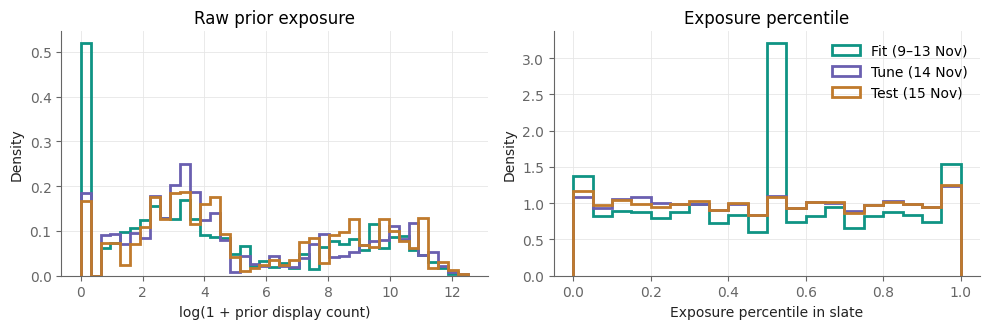

In [ ]:
raw = {}
for split, fname in {"fit": "fit_candidates_sampled", "tune": "tune_candidates", "eval": "eval_candidates"}.items():
    c = pd.read_parquet(PROCESSED_DIR / f"{fname}.parquet", columns=["prior_exposure_count"])["prior_exposure_count"]
    raw[split] = np.log1p(c.sample(n=min(1_000_000, len(c)), random_state=42).to_numpy())
    del c; gc.collect()

display(pd.DataFrame({SPLITS[s]: describe(pd.Series(np.expm1(v))) for s, v in raw.items()}).T.round(1)
        .rename(columns=lambda c: f"prior displays: {c}"))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
bins_raw = np.linspace(0, max(v.max() for v in raw.values()), 40)
for split, v in raw.items():
    axes[0].hist(v, bins=bins_raw, density=True, histtype="step", linewidth=2, color=COLOURS[split], label=SPLITS[split])
    axes[1].hist(samples[split]["slate_exposure_pct"], bins=np.linspace(0, 1, 21), density=True,
                 histtype="step", linewidth=2, color=COLOURS[split], label=SPLITS[split])
axes[0].set(xlabel="log(1 + prior display count)", ylabel="Density", title="Raw prior exposure")
axes[1].set(xlabel="Exposure percentile in slate", ylabel="Density", title="Exposure percentile")
axes[1].legend(frameon=False)
fig.tight_layout()
save(fig, "fig_exposure_raw_vs_percentile")
plt.show()

### 12.3 Feature distributions on the Test day
One panel per numeric feature, from a 1M-row random sample of the Test candidates (history length per impression).

saved /content/figures/fig_feature_distributions_test.png


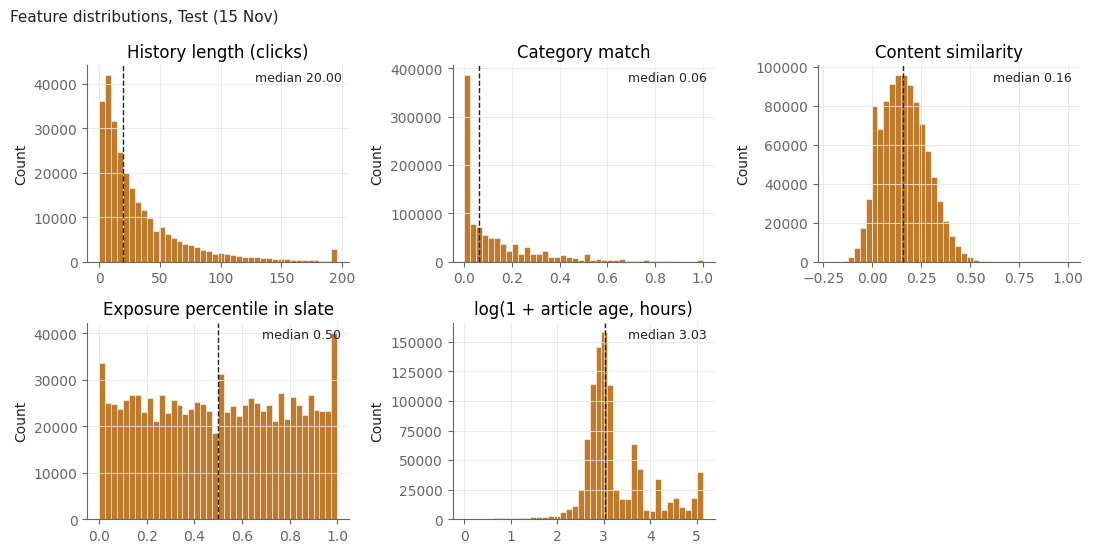

In [ ]:
test = samples["eval"]
fig, axes = plt.subplots(2, 3, figsize=(11, 5.6))
for ax, col in zip(axes.flat, NUMERIC):
    v = test.groupby("impression_id")["hist_len"].first() if col == "hist_len" else test[col]
    if col == "hist_len":
        v = v.clip(upper=v.quantile(0.99))                      # long tail clipped at the 99th percentile
    ax.hist(v, bins=40, color=COLOURS["eval"], edgecolor="white", linewidth=0.4)
    ax.set(title=LABELS[col], ylabel="Count")
    ax.axvline(v.median(), color=INK, linewidth=1, linestyle="--")
    ax.annotate(f"median {v.median():.2f}", xy=(0.97, 0.92), xycoords="axes fraction", ha="right", color=INK, fontsize=9)
axes.flat[-1].axis("off")
fig.suptitle("Feature distributions, Test (15 Nov)", x=0.01, ha="left", fontsize=11, color=INK)
fig.tight_layout()
save(fig, "fig_feature_distributions_test")
plt.show()

### 12.4 Click rate by feature level (Tune)
Candidates are split into 10 equal-sized groups (deciles) by each feature, from lowest to highest; the line shows the click rate in each decile. A slope means the feature separates clicked from non-clicked articles. The dashed line is the overall click rate.

saved /content/figures/fig_click_rate_by_feature_tune.png


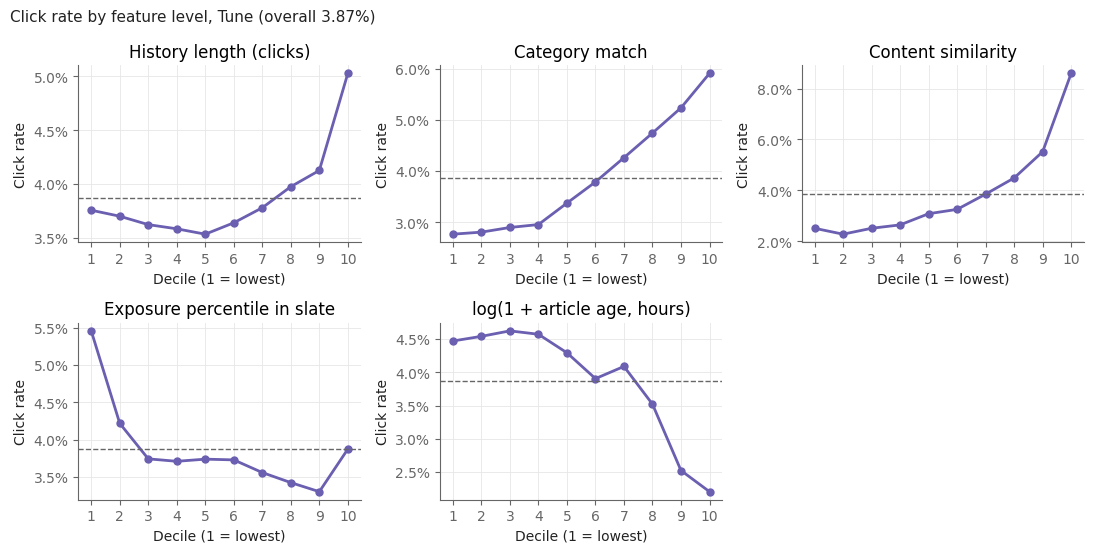

,click rate (lowest decile),click rate (highest decile)
feature,,
hist_len,0.0376,0.0503
cat_match,0.0277,0.0591
user_article_sim,0.0251,0.0860
slate_exposure_pct,0.0546,0.0387
log_article_age_hours,0.0447,0.0221


In [ ]:
tune = samples["tune"]
base = tune["label"].mean()
fig, axes = plt.subplots(2, 3, figsize=(11, 5.6))
rows = []
for ax, col in zip(axes.flat, NUMERIC):
    deciles = pd.qcut(tune[col].rank(method="first"), 10, labels=False) + 1
    g = tune.groupby(deciles)["label"].mean()
    ax.plot(g.index, g.values, marker="o", markersize=5, linewidth=2, color=COLOURS["tune"])
    ax.axhline(base, color=MUTED, linewidth=1, linestyle="--")
    ax.set(title=LABELS[col], xlabel="Decile (1 = lowest)", ylabel="Click rate", xticks=range(1, 11))
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=1))
    rows.append({"feature": col, "click rate (lowest decile)": g.iloc[0], "click rate (highest decile)": g.iloc[-1]})
axes.flat[-1].axis("off")
fig.suptitle(f"Click rate by feature level, Tune (overall {base:.2%})", x=0.01, ha="left", fontsize=11, color=INK)
fig.tight_layout()
save(fig, "fig_click_rate_by_feature_tune")
plt.show()
display(pd.DataFrame(rows).set_index("feature").round(4))

### 12.5 Articles by category and top subcategories
Share of all articles in `news_metadata` (each article counted once).

104,151 articles | 18 categories | 285 subcategories
saved /content/figures/fig_articles_by_category.png


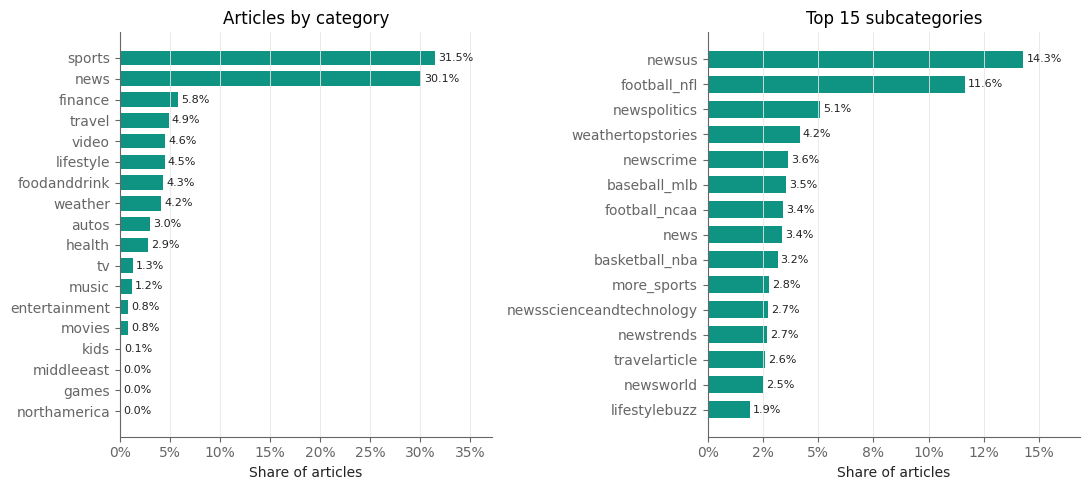

In [ ]:
news = pd.read_parquet(PROCESSED_DIR / "news_metadata.parquet", columns=["news_id", "category", "subcategory"])
news = news.drop_duplicates("news_id")
cat = news["category"].value_counts(normalize=True).sort_values()
sub = news["subcategory"].value_counts(normalize=True).head(15).sort_values()
print(f"{len(news):,} articles | {news['category'].nunique()} categories | {news['subcategory'].nunique()} subcategories")

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, s, title in [(axes[0], cat, "Articles by category"), (axes[1], sub, "Top 15 subcategories")]:
    ax.barh(s.index, s.values, color=COLOURS["fit"], height=0.7)
    for y, v in enumerate(s.values):
        ax.text(v + s.max() * 0.01, y, f"{v:.1%}", va="center", fontsize=8, color=INK)
    ax.set(title=title, xlabel="Share of articles")
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0, s.max() * 1.18)
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
fig.tight_layout()
save(fig, "fig_articles_by_category")
plt.show()